Cell 1: Paths and the station list

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Works whether the notebook runs from notebooks/ or the project root.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "cpcb"

stations = pd.read_csv(RAW / "stations_info.csv")
stations["city"] = stations["city"].str.strip()
print(stations.shape)
stations.head()

(453, 8)


,file_name,state,city,agency,station_location,start_month,start_month_num,start_year
0,AP001,Andhra Pradesh,Tirupati,APPCB,"Tirumala, Tirupati",July,7,2016
1,AP002,Andhra Pradesh,Vijayawada,APPCB,"PWD Grounds, Vijayawada",May,5,2017
2,AP003,Andhra Pradesh,Visakhapatnam,APPCB,"GVM Corporation, Visakhapatnam",July,7,2017
3,AP004,Andhra Pradesh,Rajamahendravaram,APPCB,"Anand Kala Kshetram, Rajamahendravaram",September,9,2017
4,AP005,Andhra Pradesh,Amaravati,APPCB,"Secretariat, Amaravati",November,11,2017


Cell 2: Load PM2.5 from all 453 stations

In [2]:
PM = "PM2.5 (ug/m3)"
frames = []
for code in stations["file_name"]:
    path = RAW / f"{code}.csv"
    if not path.exists():
        print("missing file:", code)
        continue
    df = pd.read_csv(path, usecols=lambda c: c in ("From Date", PM))
    if PM not in df.columns:
        print("no PM2.5 column:", code)
        continue
    df["station"] = code
    frames.append(df)

pm = pd.concat(frames, ignore_index=True)
pm["time"] = pd.to_datetime(pm["From Date"], format="%Y-%m-%d %H:%M:%S", errors="coerce")
pm = pm.rename(columns={PM: "pm25"}).drop(columns="From Date")
pm["city"] = pm["station"].map(stations.set_index("file_name")["city"])
print(pm.shape, "| unparsed timestamps:", pm["time"].isna().sum())
pm.head()

no PM2.5 column: DL018
no PM2.5 column: KA005
no PM2.5 column: KA006
no PM2.5 column: TN007
(14098696, 4) | unparsed timestamps: 0


,pm25,station,time,city
0,10.67,AP001,2016-07-01 10:00:00,Tirupati
1,2.00,AP001,2016-07-01 11:00:00,Tirupati
2,NaN,AP001,2016-07-01 12:00:00,Tirupati
3,NaN,AP001,2016-07-01 13:00:00,Tirupati
4,20.50,AP001,2016-07-01 14:00:00,Tirupati


Cell 3: Hourly or 15-minute? And per-station coverage

In [3]:
pm = pm.sort_values(["station", "time"]).reset_index(drop=True)
gap_min = pm.groupby("station")["time"].diff().dt.total_seconds() / 60
print("Most common gap between rows (minutes):")
print(gap_min.value_counts().head())

summary = pm.groupby("station").agg(first=("time", "min"), last=("time", "max"),
                                    valid=("pm25", "count"))
summary["expected_hours"] = (summary["last"] - summary["first"]).dt.total_seconds() / 3600 + 1
summary["missing_pct"] = (100 * (1 - summary["valid"] / summary["expected_hours"])).round(1)
summary = summary.join(stations.set_index("file_name")[["state", "city"]])
print("Data range:", pm["time"].min(), "to", pm["time"].max())
summary.sort_values("missing_pct").head(10)

Most common gap between rows (minutes):
time
60.0       14098246
10620.0           1
Name: count, dtype: int64
Data range: 2010-01-01 00:00:00 to 2023-03-31 23:00:00


,first,last,valid,expected_hours,missing_pct,state,city
station,,,,,,,
RJ026,2023-03-07 16:00:00,2023-03-31 23:00:00,584,584.0,0.0,Rajasthan,Jhunjhunu
RJ020,2023-02-28 17:00:00,2023-03-31 23:00:00,749,751.0,0.3,Rajasthan,Barmer
RJ018,2023-02-03 17:00:00,2023-03-31 23:00:00,1343,1351.0,0.6,Rajasthan,Bikaner
RJ034,2023-03-06 17:00:00,2023-03-31 23:00:00,602,607.0,0.8,Rajasthan,Sikar
RJ021,2023-02-01 15:00:00,2023-03-31 23:00:00,1387,1401.0,1.0,Rajasthan,Bharatpur
RJ028,2023-03-13 16:00:00,2023-03-31 23:00:00,435,440.0,1.1,Rajasthan,Jodhpur
RJ019,2023-02-03 18:00:00,2023-03-31 23:00:00,1333,1350.0,1.3,Rajasthan,Kota
RJ014,2023-02-10 09:00:00,2023-03-31 23:00:00,1174,1191.0,1.4,Rajasthan,Jodhpur
DL029,2018-03-01 00:00:00,2023-03-31 23:00:00,43892,44568.0,1.5,Delhi,Delhi


Cell 4: Data-quality checks

In [4]:
v = pm["pm25"]
print(v.describe(percentiles=[0.01, 0.5, 0.99]).round(1))
print("negative values:", (v < 0).sum())
print("exactly zero:   ", (v == 0).sum())
print("above 1000:     ", (v > 1000).sum())

# "Stuck" sensors: the same value repeated for 24+ consecutive rows.
new_run = (v != v.shift()) | (pm["station"] != pm["station"].shift())
run_len = pm.groupby(new_run.cumsum())["pm25"].transform("size")
print("readings inside 24+ identical runs:", ((run_len >= 24) & v.notna()).sum())

count    10357694.0
mean           68.4
std            76.2
min             0.0
1%              3.0
50%            45.4
99%           367.8
max          1000.0
Name: pm25, dtype: float64
negative values: 0
exactly zero:    0
above 1000:      0
readings inside 24+ identical runs: 31452


Cell 5: City-level coverage in recent years

In [5]:
pm["hour"] = pm["time"].dt.floor("h")
city_hour = (pm.dropna(subset=["pm25"])
               .groupby(["city", "hour"])["pm25"].mean()
               .reset_index())

start, end = pd.Timestamp("2020-01-01"), pm["time"].max()
recent = city_hour[(city_hour["hour"] >= start) & (city_hour["hour"] <= end)]
total_hours = int((end - start).total_seconds() / 3600) + 1

city_stats = pd.DataFrame({
    "stations": stations.groupby("city").size(),
    "first_year": city_hour.groupby("city")["hour"].min().dt.year,
    "coverage_pct_since_2020": (recent.groupby("city").size() / total_hours * 100).round(1),
})
city_stats.sort_values("coverage_pct_since_2020", ascending=False).head(30)

,stations,first_year,coverage_pct_since_2020
city,,,
Bengaluru,12,2015.0,100.0
Hyderabad,14,2015.0,100.0
Gurugram,4,2016.0,100.0
Howrah,3,2018.0,100.0
Delhi,40,2010.0,100.0
Chennai,9,2015.0,100.0
Mumbai,21,2013.0,100.0
Noida,4,2012.0,100.0
Kolkata,7,2018.0,100.0


Cell 6: Which cities appear in the live feed?

In [6]:
live_file = sorted((ROOT / "data" / "raw" / "live" / "datagov").glob("*/*.csv"))[-1]
live = pd.read_csv(live_file)
live["city"] = live["city"].str.strip()
print("live snapshot:", live_file.name)

city_stats["live_stations"] = live.groupby("city")["station"].nunique()
city_stats["live_stations"] = city_stats["live_stations"].fillna(0).astype(int)

# Kaggle cities with good coverage but no live match: possible spelling differences.
no_match = city_stats[(city_stats["live_stations"] == 0) & (city_stats["coverage_pct_since_2020"] > 50)]
print("Good history but NOT found in live feed:", list(no_match.index))
print("All live city names:", sorted(live["city"].unique()))

live snapshot: 1135.csv
Good history but NOT found in live feed: ['Bulandshahr', 'Chikkamagaluru', 'Davanagere', 'Ernakulam', 'Katni', 'Kochi', 'Kollam', 'Kozhikode', 'Nandesari', 'Singrauli']
All live city names: ['Agartala', 'Agra', 'Ahmedabad', 'Ahmednagar', 'Aizawl', 'Ajmer', 'Akola', 'Alwar', 'Amaravati', 'Ambala', 'Ambernath', 'Amravati', 'Amritsar', 'Anantapur', 'Angul', 'Ankleshwar', 'Anpara', 'Araria', 'Arrah', 'Asansol', 'Aurangabad', 'Baddi', 'Badlapur', 'Bagalkot', 'Baghpat', 'Bahadurgarh', 'Balasore', 'Ballabgarh', 'Banswara', 'Baran', 'Barbil', 'Bareilly', 'Baripada', 'Barmer', 'Barrackpore', 'Bathinda', 'Beed', 'Begusarai', 'Belapur', 'Belgaum', 'Bengaluru', 'Bettiah', 'Bhagalpur', 'Bharatpur', 'Bhavnagar', 'Bhilai', 'Bhilwara', 'Bhiwadi', 'Bhiwandi', 'Bhiwani', 'Bhopal', 'Bhubaneswar', 'Bihar Sharif', 'Bikaner', 'Bilaspur', 'Boisar', 'Brajrajnagar', 'Bundi', 'Buxar', 'Byasanagar', 'Byrnihat', 'Chamarajanagar', 'Chandigarh', 'Chandrapur', 'Charkhi Dadri', 'Chennai', 'Chh

Cell 7: The candidate shortlist

In [7]:
candidates = city_stats[(city_stats["coverage_pct_since_2020"] >= 70) &
                        (city_stats["live_stations"] >= 1)]
candidates = candidates.join(stations.groupby("city")["state"].first())
candidates.sort_values("coverage_pct_since_2020", ascending=False)

,stations,first_year,coverage_pct_since_2020,live_stations,state
city,,,,,
Delhi,40,2010.0,100.0,57,Delhi
Chennai,9,2015.0,100.0,6,Tamil Nadu
Bengaluru,12,2015.0,100.0,9,Karnataka
Howrah,3,2018.0,100.0,5,West Bengal
Gurugram,4,2016.0,100.0,4,Haryana
...,...,...,...,...,...
Ratlam,1,2018.0,78.5,1,Madhya Pradesh
Shivamogga,1,2020.0,76.5,1,Karnataka
Baghpat,2,2018.0,74.4,1,Uttar Pradesh


Cell 8: Seasonal and daily patterns

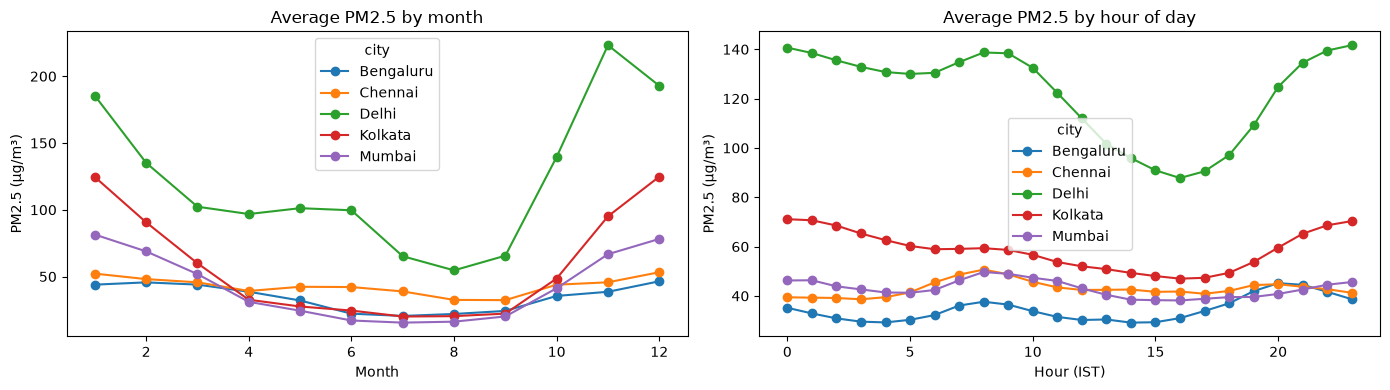

In [8]:
show = ["Delhi", "Mumbai", "Chennai", "Kolkata", "Bengaluru"]
show = [c for c in show if c in city_hour["city"].unique()]
d = city_hour[city_hour["city"].isin(show)]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
d.groupby([d["hour"].dt.month, "city"])["pm25"].mean().unstack().plot(ax=axes[0], marker="o")
axes[0].set(title="Average PM2.5 by month", xlabel="Month", ylabel="PM2.5 (µg/m³)")
d.groupby([d["hour"].dt.hour, "city"])["pm25"].mean().unstack().plot(ax=axes[1], marker="o")
axes[1].set(title="Average PM2.5 by hour of day", xlabel="Hour (IST)", ylabel="PM2.5 (µg/m³)")
plt.tight_layout()
plt.show()

Cell 9: Check the proposed cities and get coordinates

In [9]:
proposed = ["Delhi", "Lucknow", "Patna", "Kanpur", "Jaipur", "Chandigarh",
            "Mumbai", "Ahmedabad", "Pune", "Bengaluru", "Chennai", "Hyderabad",
            "Kolkata", "Guwahati"]

# Use ALL live snapshots so far: station counts vary hour to hour.
live_all = pd.concat(pd.read_csv(f) for f in
                     (ROOT / "data" / "raw" / "live" / "datagov").glob("*/*.csv"))
live_all["city"] = live_all["city"].str.strip()
live_all[["latitude", "longitude"]] = live_all[["latitude", "longitude"]].astype(float)

check = city_stats.reindex(proposed)[["stations", "first_year", "coverage_pct_since_2020"]]
check["live_stations"] = live_all.groupby("city")["station"].nunique().reindex(proposed)
check[["lat", "lon"]] = live_all.groupby("city")[["latitude", "longitude"]].mean().round(4).reindex(proposed)
print("readings exactly 1000:", (pm["pm25"] == 1000).sum())
check

readings exactly 1000: 292


,stations,first_year,coverage_pct_since_2020,live_stations,lat,lon
city,,,,,,
Delhi,40,2010.0,100.0,57,28.6380,77.1582
Lucknow,7,2015.0,100.0,6,26.8546,80.9491
Patna,6,2013.0,100.0,4,25.5983,85.0939
Kanpur,4,2015.0,99.6,2,26.4493,80.3250
Jaipur,5,2017.0,99.9,6,26.8934,75.7890
Chandigarh,3,2019.0,99.2,2,30.7435,76.7693
Mumbai,21,2013.0,100.0,23,19.0797,72.8643
Ahmedabad,9,2015.0,97.5,8,23.0333,72.5655
Pune,8,2015.0,83.9,7,18.5147,73.8634
